# Comparison of two groups

We compare the survivor functions of two groups, by hand: the Kaplan-Meier estimator of each group, and the log-rank, Wilcoxon and Peto-Peto tests of the hypothesis that the two groups have the same survivor function.

The data are the survival times, in months, of 45 women with breast cancer. The tumours were stained with a marker (HPA) and classified as negatively (`stain` 1) or positively (`stain` 2) stained.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm, chi2

In [2]:
ALPHA = 0.05

In [3]:
# Colors shared by all the plots
GROUP_COLORS = {'Stain Negative': '#1f4e79', 'Stain Positive': '#E69F00'}
ref_color = '#333333'

## The data

In [4]:
DatOriginal = pd.read_csv("data/breast_cancer_prognosis.dat", sep=r"\s+")
DatOriginal = DatOriginal.rename({'time':'Time'}, axis=1)
DatOriginal['Censored'] = (DatOriginal['status']-1)*(-1)

Split the data for each group

In [5]:
DatOriginalNegative = DatOriginal[DatOriginal['stain']==1]
DatOriginalNegative = DatOriginalNegative[['Time', 'Censored']]

In [6]:
DatOriginalPositive = DatOriginal[DatOriginal['stain']==2]
DatOriginalPositive = DatOriginalPositive[['Time', 'Censored']]

In [7]:
pd.DataFrame(
    {
        'Women': [len(DatOriginalNegative), len(DatOriginalPositive)],
        'Deaths': [(DatOriginalNegative['Censored']==0).sum(), (DatOriginalPositive['Censored']==0).sum()],
        'Censored': [DatOriginalNegative['Censored'].sum(), DatOriginalPositive['Censored'].sum()]
    },
    index=GROUP_COLORS.keys()
)

,Women,Deaths,Censored
Stain Negative,13,5,8
Stain Positive,32,21,11


## Functions

Function to create the life-table

In [8]:
def CreateLifeTable(data):

    datalifetable = pd.DataFrame(
        {
            'tj': np.unique([0] + data.loc[data['Censored']==0, 'Time'].sort_values().to_list())
        }
    )

    datalifetable = datalifetable.reset_index(drop=True)

    datalifetable['tj+1'] = datalifetable['tj'].to_list()[1:] + [np.inf]

    n_list, d_list, c_list = [], [], []

    for j in range(len(datalifetable)):

        if j==0:
            n = len(data)
        else:
            n = n-d-c

        d = sum(data.loc[data['Censored']==0, 'Time'] == datalifetable.loc[j]['tj'])
        c = sum(
                (data.loc[data['Censored']==1, 'Time'] >= datalifetable.loc[j]['tj'])
                & (data.loc[data['Censored']==1, 'Time'] < datalifetable.loc[j]['tj+1'])
            )

        n_list.append(n)
        d_list.append(d)
        c_list.append(c)

    datalifetable['nj'] = n_list
    datalifetable['dj'] = d_list
    datalifetable['cj'] = c_list

    return datalifetable

Function to create the life-table of the combined groups. The intervals start at the death times of the two groups together. At each time $t_j$ there are $n_{1j}$ and $n_{2j}$ women at risk and $d_{1j}$ and $d_{2j}$ deaths in each group, $n_j$ and $d_j$ in total.

If the two groups have the same survivor function, the $d_j$ deaths are distributed between the groups in proportion to the women at risk. So the number of deaths in the first group has mean and variance (hypergeometric distribution)

$$
e_{1j}=\frac{n_{1j}d_j}{n_j},\qquad v_{1j}=\frac{n_{1j}n_{2j}d_j(n_j-d_j)}{n_j^2(n_j-1)}.
$$

In [9]:
def CreateLifeTableCombined(data, datagroup1, datagroup2):

    datalifetablecombined = pd.DataFrame(
        {
            'tj': np.unique([0] + data.loc[data['Censored']==0, 'Time'].sort_values().to_list())
        }
    )

    datalifetablecombined = datalifetablecombined.reset_index(drop=True)

    datalifetablecombined['tj+1'] = datalifetablecombined['tj'].to_list()[1:] + [np.inf]

    n1_list, d1_list, c1_list = [], [], []
    n2_list, d2_list, c2_list = [], [], []

    for j in range(len(datalifetablecombined)):

        if j==0:
            n1 = len(datagroup1)
            n2 = len(datagroup2)
        else:
            n1 = n1-d1-c1
            n2 = n2-d2-c2

        d1 = sum(data.loc[(data['Censored']==0) & (data['stain']==1), 'Time'] == datalifetablecombined.loc[j]['tj'])
        c1 = sum(
                (data.loc[(data['Censored']==1) & (data['stain']==1), 'Time'] >= datalifetablecombined.loc[j]['tj'])
                & (data.loc[(data['Censored']==1) & (data['stain']==1), 'Time'] < datalifetablecombined.loc[j]['tj+1'])
            )

        d2 = sum(data.loc[(data['Censored']==0) & (data['stain']==2), 'Time'] == datalifetablecombined.loc[j]['tj'])
        c2 = sum(
                (data.loc[(data['Censored']==1) & (data['stain']==2), 'Time'] >= datalifetablecombined.loc[j]['tj'])
                & (data.loc[(data['Censored']==1) & (data['stain']==2), 'Time'] < datalifetablecombined.loc[j]['tj+1'])
            )

        n1_list.append(n1)
        d1_list.append(d1)

        n2_list.append(n2)
        d2_list.append(d2)

    datalifetablecombined['n1j'] = n1_list
    datalifetablecombined['d1j'] = d1_list

    datalifetablecombined['n2j'] = n2_list
    datalifetablecombined['d2j'] = d2_list

    datalifetablecombined['nj'] = datalifetablecombined['n1j'] + datalifetablecombined['n2j']
    datalifetablecombined['dj'] = datalifetablecombined['d1j'] + datalifetablecombined['d2j']

    datalifetablecombined['e1j'] = datalifetablecombined['n1j'] * datalifetablecombined['dj'] / datalifetablecombined['nj']
    datalifetablecombined['v1j'] = datalifetablecombined['n1j'] * datalifetablecombined['n2j'] * datalifetablecombined['dj'] * (datalifetablecombined['nj'] - datalifetablecombined['dj']) / (datalifetablecombined['nj']**2 * (datalifetablecombined['nj']-1))

    return datalifetablecombined

Function to calculate the survivor function, cumulative hazard function, and hazard function using the Kaplan-Meier approach

In [10]:
def KaplanMeier(datalifetable):
    datakm = datalifetable.copy()

    # Estimate survivor function, cumulative hazard function and hazard function
    datakm['Survivor'] = np.cumprod((datakm['nj'] - datakm['dj']) / datakm['nj'])
    datakm['CumHazard'] = -np.log(datakm['Survivor'])
    datakm['Hazard'] = datakm['dj'] / (datakm['nj'] * (datakm['tj+1'] - datakm['tj']))

    # Estimate standard deviation of the cumulative hazard function, and survivor function
    datakm['StdCumHazard'] = np.sqrt(np.cumsum(datakm['dj'] / (datakm['nj'] * (datakm['nj'] - datakm['dj']))))
    datakm['StdSurvivor'] = datakm['Survivor'] * datakm['StdCumHazard']

    return datakm

Function to compute confidence intervals for the cumulative hazard function, and the survivor function

In [11]:
def GetConfidenceInterval(datasurvivor, alpha):

    # The interval is only defined where the cumulative hazard is positive
    positive = datasurvivor['CumHazard'] > 0
    cumhazard = datasurvivor['CumHazard'].where(positive)

    datasurvivor['LowerLogCumHazar'] = norm.ppf(alpha/2, np.log(cumhazard), datasurvivor['StdCumHazard'] / cumhazard)
    datasurvivor['UpperLogCumHazar'] = norm.ppf(1-alpha/2, np.log(cumhazard), datasurvivor['StdCumHazard'] / cumhazard)

    datasurvivor['LowerCumHazard'] = np.exp(datasurvivor['LowerLogCumHazar'])
    datasurvivor['UpperCumHazard'] = np.exp(datasurvivor['UpperLogCumHazar'])

    datasurvivor['LowerSurvivor'] = np.exp(-datasurvivor['UpperCumHazard'])
    datasurvivor['UpperSurvivor'] = np.exp(-datasurvivor['LowerCumHazard'])

    datasurvivor = datasurvivor.drop(['LowerLogCumHazar', 'UpperLogCumHazar'], axis=1)

    return datasurvivor

Function to test the hypothesis of no difference between the groups. The three tests add the differences between observed and expected deaths in the first group over the death times, with different weights $w_j$:

$$
U=\sum_j w_j(d_{1j}-e_{1j}),\qquad V=\sum_j w_j^2v_{1j},\qquad W=\frac{U^2}{V}\sim\chi^2_1\ \text{under the hypothesis.}
$$

- Log-rank: $w_j=1$, all the death times count the same.
- Wilcoxon: $w_j=n_j$, the early times, with more women at risk, count more.
- Peto-Peto: $w_j=\hat S(t_j)$, the Kaplan-Meier estimator of the two groups combined.

In [12]:
def HypothesisNoDifference(datasurvivorcombined):

    # log-rank test
    Ul = sum(datasurvivorcombined['d1j'] - datasurvivorcombined['e1j'])
    Vl = sum(datasurvivorcombined['v1j'])

    Wl = Ul**2 / Vl

    # Wilcoxon test
    Uw = sum(datasurvivorcombined['nj']*(datasurvivorcombined['d1j'] - datasurvivorcombined['e1j']))
    Vw = sum(datasurvivorcombined['nj']**2*datasurvivorcombined['v1j'])

    Ww = Uw**2 / Vw

    # Peto-Peto test
    Up = sum(datasurvivorcombined['Survivor']*(datasurvivorcombined['d1j'] - datasurvivorcombined['e1j']))
    Vp = sum(datasurvivorcombined['Survivor']**2*datasurvivorcombined['v1j'])

    Wp = Up**2 / Vp

    return pd.DataFrame(
        {
            'Statistic':[Wl, Ww, Wp],
            'PValue':[chi2.sf(Wl, 1), chi2.sf(Ww, 1), chi2.sf(Wp, 1)]
        },
        index=['Log-rank', 'Wilcoxon', 'Peto-Peto']
    )

Functions for the plots

In [13]:
T_END = 1.03 * DatOriginal['Time'].max()   # the last step is drawn up to here

def StepValues(datasurvivor, column):
    # Times and values of a step function, extended to the end of the plot
    t = np.append(datasurvivor['tj'].to_numpy(), T_END)
    values = datasurvivor[column].to_numpy()
    return t, np.append(values, values[-1])

def PlotSurvivor(ax, datasurvivor, color, label, data=None, band=False, ls='-'):
    if band:
        t, lower = StepValues(datasurvivor, 'LowerSurvivor')
        t, upper = StepValues(datasurvivor, 'UpperSurvivor')
        ax.fill_between(t, lower, upper, step='post', color=color, alpha=0.25, lw=0)
    t, values = StepValues(datasurvivor, 'Survivor')
    ax.step(t, values, where='post', color=color, lw=2, ls=ls, label=label)
    if data is not None:
        # A tick on the curve at each censored time
        censored = data.loc[data['Censored']==1, 'Time'].to_numpy()
        position = np.searchsorted(datasurvivor['tj'].to_numpy(), censored, side='right') - 1
        ax.plot(censored, datasurvivor['Survivor'].to_numpy()[position], '|', color=color, markersize=11, markeredgewidth=2)

def FormatSurvivorPlot(ax, title):
    ax.set_xlabel('Time (months)')
    ax.set_ylabel('Survivor function')
    ax.set_xlim(0, T_END)
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc='lower left', frameon=False)
    ax.grid(True, alpha=0.25)

## Kaplan-Meier estimator of each group

In [14]:
DatLifeTableNegative = CreateLifeTable(DatOriginalNegative)
DatLifeTablePositive = CreateLifeTable(DatOriginalPositive)

In [15]:
DatKaplanMeierNegative = KaplanMeier(DatLifeTableNegative)
DatKaplanMeierNegative = GetConfidenceInterval(DatKaplanMeierNegative, ALPHA)

DatKaplanMeierPositive = KaplanMeier(DatLifeTablePositive)
DatKaplanMeierPositive = GetConfidenceInterval(DatKaplanMeierPositive, ALPHA)

In [16]:
DatKaplanMeierNegative[['tj', 'nj', 'dj', 'cj', 'Survivor', 'LowerSurvivor', 'UpperSurvivor']].round(4)

,tj,nj,dj,cj,Survivor,LowerSurvivor,UpperSurvivor
0,0,13,0,0,1.0000,NaN,NaN
1,23,13,1,0,0.9231,0.5664,0.9888
2,47,12,1,0,0.8462,0.5122,0.9591
3,69,11,1,4,0.7692,0.4421,0.9191
4,148,6,1,0,0.6410,0.2818,0.8555
5,181,5,1,4,0.5128,0.1756,0.7738


In [17]:
DatKaplanMeierPositive[['tj', 'nj', 'dj', 'cj', 'Survivor', 'LowerSurvivor', 'UpperSurvivor']].round(4)

,tj,nj,dj,cj,Survivor,LowerSurvivor,UpperSurvivor
0,0,32,0,0,1.0000,NaN,NaN
1,5,32,1,0,0.9688,0.7982,0.9955
2,8,31,1,0,0.9375,0.7725,0.9840
3,10,30,1,0,0.9062,0.7369,0.9688
4,13,29,1,0,0.8750,0.7004,0.9512
5,18,28,1,0,0.8438,0.6646,0.9318
6,24,27,1,0,0.8125,0.6295,0.9111
7,26,26,2,0,0.7500,0.5618,0.8663
8,31,24,1,0,0.7188,0.5291,0.8426
9,35,23,1,0,0.6875,0.4971,0.8180


The women with a positively stained tumour have a lower estimated survival at all times, but the confidence intervals overlap.

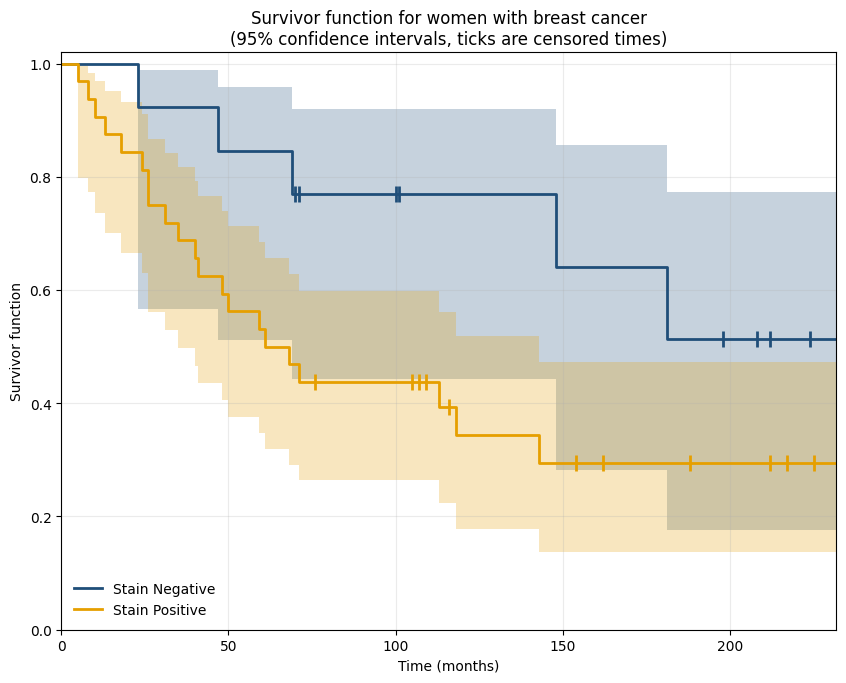

In [18]:
fig, ax = plt.subplots(figsize=(10, 7.5))
PlotSurvivor(ax, DatKaplanMeierNegative, GROUP_COLORS['Stain Negative'], 'Stain Negative', DatOriginalNegative, band=True)
PlotSurvivor(ax, DatKaplanMeierPositive, GROUP_COLORS['Stain Positive'], 'Stain Positive', DatOriginalPositive, band=True)
FormatSurvivorPlot(ax, f"Survivor function for women with breast cancer\n({(1-ALPHA)*100:.0f}% confidence intervals, ticks are censored times)")

## The two groups combined

Under the hypothesis of no difference, the two groups share one survivor function, which is estimated with all the women together.

In [19]:
DatLifeTableCombined = CreateLifeTableCombined(DatOriginal, DatOriginalNegative, DatOriginalPositive)
DatKaplanMeierCombined = KaplanMeier(DatLifeTableCombined)

In [20]:
DatKaplanMeierCombined[['tj', 'n1j', 'd1j', 'n2j', 'd2j', 'nj', 'dj', 'e1j', 'v1j', 'Survivor']].round(4)

,tj,n1j,d1j,n2j,d2j,nj,dj,e1j,v1j,Survivor
0,0,13,0,32,0,45,0,0.0000,0.0000,1.0000
1,5,13,0,32,1,45,1,0.2889,0.2054,0.9778
2,8,13,0,31,1,44,1,0.2955,0.2082,0.9556
3,10,13,0,30,1,43,1,0.3023,0.2109,0.9333
4,13,13,0,29,1,42,1,0.3095,0.2137,0.9111
5,18,13,0,28,1,41,1,0.3171,0.2165,0.8889
6,23,13,1,27,0,40,1,0.3250,0.2194,0.8667
7,24,12,0,27,1,39,1,0.3077,0.2130,0.8444
8,26,12,0,26,2,38,2,0.6316,0.4205,0.8000
9,31,12,0,24,1,36,1,0.3333,0.2222,0.7778


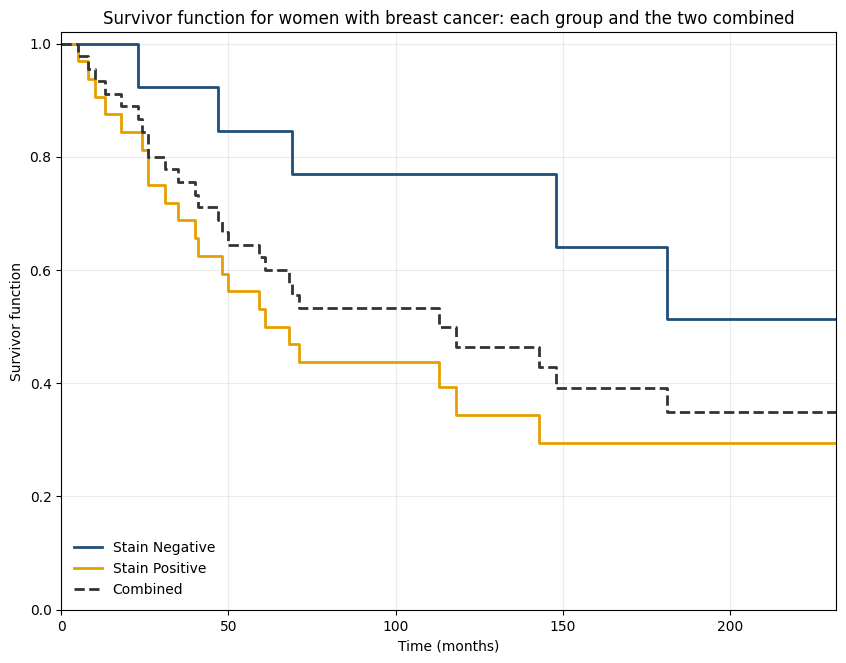

In [21]:
fig, ax = plt.subplots(figsize=(10, 7.5))
PlotSurvivor(ax, DatKaplanMeierNegative, GROUP_COLORS['Stain Negative'], 'Stain Negative')
PlotSurvivor(ax, DatKaplanMeierPositive, GROUP_COLORS['Stain Positive'], 'Stain Positive')
PlotSurvivor(ax, DatKaplanMeierCombined, ref_color, 'Combined', ls='--')
FormatSurvivorPlot(ax, "Survivor function for women with breast cancer: each group and the two combined")

## Tests of no difference

In [22]:
Tests = HypothesisNoDifference(DatKaplanMeierCombined)
Tests

,Statistic,PValue
Log-rank,3.514993,0.060816
Wilcoxon,4.179966,0.040905
Peto-Peto,4.135244,0.041999


The figure shows where the statistics come from. On the left, the accumulated difference between observed and expected deaths in the negative group: it goes down almost all the time, that group has fewer deaths than expected if there were no difference. On the right, the weight that each test gives to each death time (relative to the first one): the Wilcoxon and Peto-Peto tests give less weight to the late times, where few women remain.

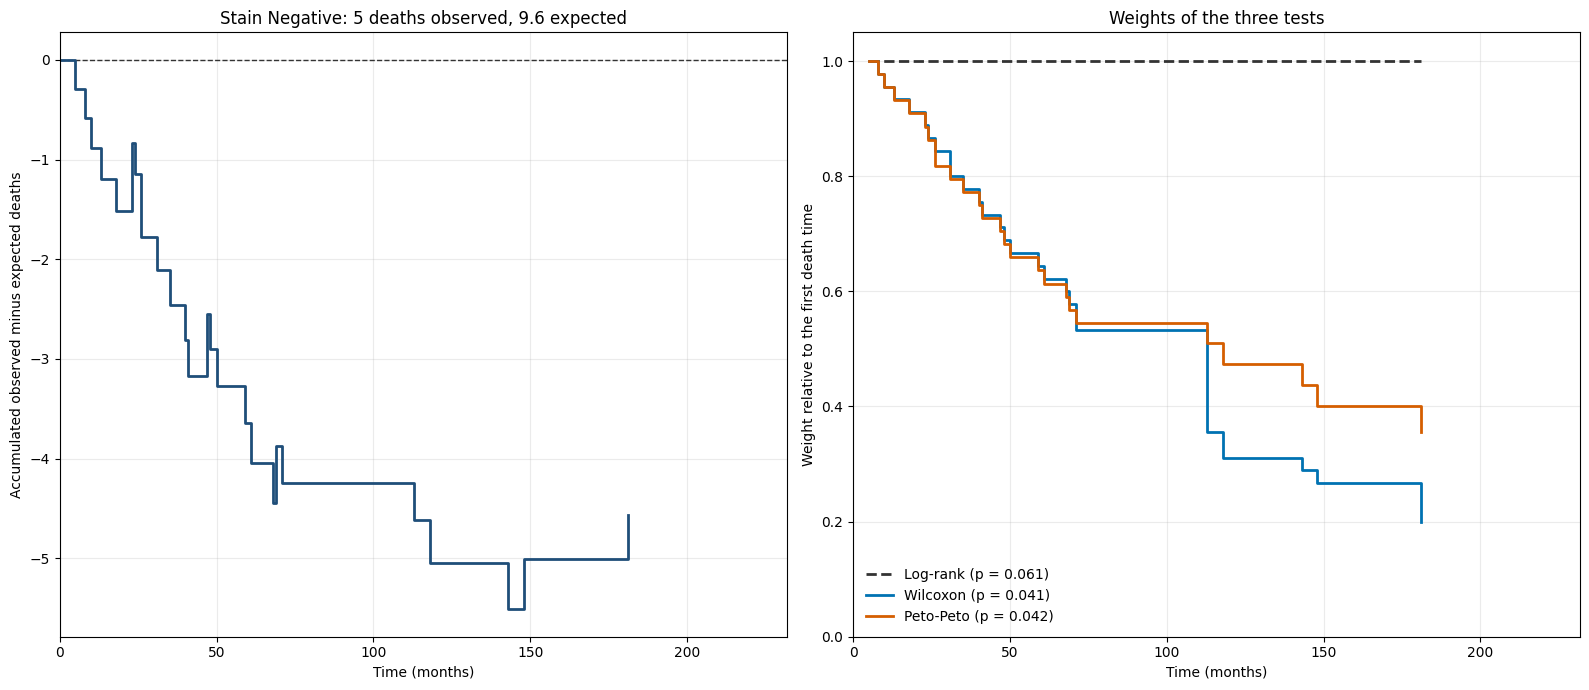

In [23]:
Events = DatKaplanMeierCombined[DatKaplanMeierCombined['dj'] > 0]
Difference = Events['d1j'] - Events['e1j']

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].axhline(0, color=ref_color, lw=1, ls='--')
axes[0].step(np.append(0, Events['tj']), np.append(0, np.cumsum(Difference)), where='post',
             color=GROUP_COLORS['Stain Negative'], lw=2)
axes[0].set_xlabel('Time (months)')
axes[0].set_ylabel('Accumulated observed minus expected deaths')
axes[0].set_title(f"Stain Negative: {Events['d1j'].sum()} deaths observed, {Events['e1j'].sum():.1f} expected")

weights = {'Log-rank': np.ones(len(Events)), 'Wilcoxon': Events['nj'], 'Peto-Peto': Events['Survivor']}
for (name, w), color, ls in zip(weights.items(), [ref_color, '#0072B2', '#D55E00'], ['--', '-', '-']):
    w = np.asarray(w, dtype=float)
    axes[1].step(Events['tj'], w / w[0], where='post', color=color, lw=2, ls=ls,
                 label=f"{name} (p = {Tests.loc[name, 'PValue']:.3f})")
axes[1].set_xlabel('Time (months)')
axes[1].set_ylabel('Weight relative to the first death time')
axes[1].set_ylim(0, 1.05)
axes[1].set_title('Weights of the three tests')
axes[1].legend(loc='lower left', frameon=False)

for ax in axes:
    ax.set_xlim(0, T_END)
    ax.grid(True, alpha=0.25)
plt.tight_layout()